<a href="https://colab.research.google.com/github/Alyssonmach/pdi-laboratorios/blob/master/k-visao-computacional/segmentacao_pets.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Segmentação Semântica usando Redes Neurais Convolucionais
***

![image](https://user-images.githubusercontent.com/58775072/136837988-ec0cbafa-dbeb-40d5-b34f-edb208a5b56a.png)


## 1. Objetivo do Laboratório
***

- Nesse notebook será explorado o uso da arquitetura U-Net para segmentação semântica. A base de dados é constituida de ínumeros exemplos de cães e gatos, e para cada uma dessas imagens, existem máscaras que destacam a borda do animal, asua região total e a que corresponde a áream em que o animal não está presente.  

## 2. Importação dos Pacotes
***

In [1]:
import tensorflow as tf # framework de inteligência artificial  
import tensorflow_datasets as tfds # repositório de datasets provenientes do tensorflow  
import matplotlib.pyplot as plt # pacote de visualização gráfica  
import numpy as np # pacote de operações matriciais e funções matemáticas    
import urllib.request as url # pacote de gerenciamento HTTP
import random # pacote de geração randômica

## 3. Baixando os Dados
***
- Para baixar os dados, execute a célula abaixo que o processo será feito automaticamente. A fonte da base de dados é a [Oxford Pets III - Dataset](https://www.robots.ox.ac.uk/~vgg/data/pets/).

In [2]:
# baixando os dados da Oxford Pets III - Dataset
dataset, info = tfds.load(name = 'oxford_iiit_pet:3.*.*', with_info = True)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

0 examples [00:00, ? examples/s]

Shuffling and writing examples to /root/tensorflow_datasets/oxford_iiit_pet/3.2.0.incompleteF5STUW/oxford_iiit_pet-train.tfrecord


  0%|          | 0/3680 [00:00<?, ? examples/s]

0 examples [00:00, ? examples/s]

Shuffling and writing examples to /root/tensorflow_datasets/oxford_iiit_pet/3.2.0.incompleteF5STUW/oxford_iiit_pet-test.tfrecord


  0%|          | 0/3669 [00:00<?, ? examples/s]

Dataset oxford_iiit_pet downloaded and prepared to /root/tensorflow_datasets/oxford_iiit_pet/3.2.0. Subsequent calls will reuse this data.


In [15]:
# visualizando as informações do conjunto de dados
print('informações do Conjunto de Dados:\n--\n', info)
# visualizando as divisões originais do conjunto de dados
print('Subdiretórios do conjunto de dados:\n--\n', dataset.keys())

informações do Conjunto de Dados:
--
 tfds.core.DatasetInfo(
    name='oxford_iiit_pet',
    version=3.2.0,
    description='The Oxford-IIIT pet dataset is a 37 category pet image dataset with roughly 200
images for each class. The images have large variations in scale, pose and
lighting. All images have an associated ground truth annotation of breed.',
    homepage='http://www.robots.ox.ac.uk/~vgg/data/pets/',
    features=FeaturesDict({
        'file_name': Text(shape=(), dtype=tf.string),
        'image': Image(shape=(None, None, 3), dtype=tf.uint8),
        'label': ClassLabel(shape=(), dtype=tf.int64, num_classes=37),
        'segmentation_mask': Image(shape=(None, None, 1), dtype=tf.uint8),
        'species': ClassLabel(shape=(), dtype=tf.int64, num_classes=2),
    }),
    total_num_examples=7349,
    splits={
        'test': 3669,
        'train': 3680,
    },
    supervised_keys=('image', 'label'),
    citation="""@InProceedings{parkhi12a,
      author       = "Parkhi, O. M. an

In [93]:
# visualizando a quantidade de imagens de treinamento e teste
print('Quantidade de Imagens de Treinamento:', info.splits['train'].num_examples, 'Imagens')
print('Quantidade de Imagens de Teste:', info.splits['test'].num_examples, 'Imagens')

Quantidade de Imagens de Treinamento: 3680 Imagens
Quantidade de Imagens de Teste: 3669 Imagens


## 4. Preparando o Conjunto de Dados para o Algoritmo
***

* Será realizado procedimentos simples para pré-processamento dos dados, dos quais podemos destacar:
  * Aumento de dados simples invertendo a imagem;
  * Normalização dos pixels nas imagens;
  * Reajustando as dimensões das imagens;

Um outro procedimento considerado é o ajuste nos valores das máscaras. A tabela abaixo ilustra a intensidade dos pixels para cada uma das classes (rótulos) disponíveis na máscara.

|Rótulo|Nome da Classe|
|:-|:-|
|1|Região do Animal|
|2|Fundo da Imagem|
|3|Contorno do Animal|

Por conveniência, será subtraído -1 de cada uma das máscaras na imagem, para que elas fiquem no seguinte formato:

|Rótulo|Nome da Classe|
|:-|:-|
|0|Região do Animal|
|1|Fundo da Imagem|
|2|Contorno do Animal|

In [18]:
def random_flip(input_image, input_mask):
  '''
  aplica transformações  de inversão horizontais na imagem
  
  Args:
    input_image (tensor) -- imagem de entrada.
    input_mask (tensor) -- máscara de entrada.
  
  Returns:
    input_image (tensor) -- imagem transformada. 
    input_mask (tensor) -- máscara transformada.
  '''

  # aplicando a transformação de inversão horizontal em 50% das imagens
  if tf.random.uniform(()) > 0.5:
    input_image = tf.image.flip_left_right(input_image)
    input_mask = tf.image.flip_left_right(input_mask)
  
  return input_image, input_mask


In [19]:
def normalize(input_image, input_mask):
  '''
  normalizando as imagens e máscaras  

  Args:
    input_image (tensor) -- imagem de entrada.
    input_mask (tensor) -- máscara de entrada.

  Returns:
    input_image (tensor) -- imagem normalizada.
    input_mask (tensor) -- máscara normalizada.
  '''

  # normalizando a imagem de entrada para valores entre [0, 1]
  input_image = tf.cast(input_image, tf.float32) / 255.
  # subtraindo -1 das máscaras para delimitar valores entre [0, 2]
  input_mask -= 1

  return input_image, input_mask  

* **Nota 1**: O `@tf:function()` é um decorador embutido no TensorFlow 2.0, seu objetivo é converter funções escritas de forma comum no python para funções em grafo. Esse procedimento permite que a função seja mais otimizada com a arquitetura do Framework TensorFlow.
* **Nota 2**: O `Python Decorator` é uma função que assume outra função e estende o comportamento da última função sem modificá-la explicitamente.

In [20]:
@tf.function
def load_image_train(datapoint):
  '''
  redimensiona, normaliza e rotaciona os dados de treinamento 

  Args:
    datapoint (tensor) -- referências das imagens e máscaras de treinamento.

  Returns:
    input_image (tensor) -- imagem pré-processada.
    input_mask (tensor) -- máscara pré-processada.
  '''

  # redimensionando as imagens e máscaras de treinamento
  input_image = tf.image.resize(datapoint['image'], (128, 128), method = 'nearest')
  input_mask = tf.image.resize(datapoint['segmentation_mask'], (128, 128), method = 'nearest')
  # aplica inversos horizontais nas imagens de treinamento  
  input_image, input_mask = random_flip(input_image, input_mask)
  input_image, input_mask = normalize(input_image, input_mask)

  return input_image, input_mask

In [21]:
@tf.function
def load_image_test(datapoint):
  '''
  redimensiona e normaliza os dados de teste
  
  Args:
    datapoint (tensor) -- referências das imagens e máscaras de treinamento.
  Returns:
    output_image (tensor) -- imagem de saída.
    output_mask (tensor) -- máscara de saída.
  '''

  # redimensiona as imagens e máscaras de teste
  input_image = tf.image.resize(datapoint['image'], (128, 128), method = 'nearest')
  input_mask = tf.image.resize(datapoint['segmentation_mask'], (128, 128), method = 'nearest')
  # normalizando as imagens e máscaras de teste
  input_image, input_mask = normalize(input_image, input_mask)

  return input_image, input_mask

In [59]:
# visualizando o formato dos dados retornados pelo gerador de imagens
print('Dados Encontrado pelo Gerador de Imagens:\n--')
cnt = 0
for pack in dataset['train']:
  if cnt == 5:
    break 
  else:
    print('Dimensão da Imagem:', pack['image'].shape, 'Dimensão da Máscara:', pack['segmentation_mask'].shape)
  cnt += 1
print('...')

Dados Encontrado pelo Gerador de Imagens:
--
Dimensão da Imagem: (500, 500, 3) Dimensão da Máscara: (500, 500, 1)
Dimensão da Imagem: (313, 500, 3) Dimensão da Máscara: (313, 500, 1)
Dimensão da Imagem: (500, 333, 3) Dimensão da Máscara: (500, 333, 1)
Dimensão da Imagem: (375, 500, 3) Dimensão da Máscara: (375, 500, 1)
Dimensão da Imagem: (500, 333, 3) Dimensão da Máscara: (500, 333, 1)
...


* Agora já é possível usar as funções de pré-processamento dos dados de treinamento e teste. O conjunto de dados baixado já contém essas divisões. 
* **Nota**: O `tf.data.experimental.AUTOTUNE` é simplesmente uma constante igual a -1. Este valor é passado para permitir que certos métodos definam parâmetros automaticamente com base nos recursos disponíveis. Por exemplo, o parâmetro `num_parallel_calls` abaixo será definido dinamicamente com base nos núcleos de processamento disponíveis.

In [22]:
# aplicando o pré-processamento nas imagens e másaras de treinamento e teste
train = dataset['train'].map(load_image_train, num_parallel_calls = tf.data.experimental.AUTOTUNE)
test = dataset['test'].map(load_image_test) 

In [62]:
# visualizando o formato dos dados retornados pelo gerador de imagens
print('Dados Encontrado pelo Gerador de Imagens (Dados de Treinamento):\n--')
cnt = 0
for image, mask in train:
  if cnt == 5:
    break 
  else:
    print('Dimensão da Imagem:', image.shape, 'Dimensão da Máscara:', mask.shape)
  cnt += 1
print('...')

# visualizando o formato dos dados retornados pelo gerador de imagens
print('\nDados Encontrado pelo Gerador de Imagens (Dados de Teste):\n--')
cnt = 0
for image, mask in test:
  if cnt == 5:
    break 
  else:
    print('Dimensão da Imagem:', image.shape, 'Dimensão da Máscara:', mask.shape)
  cnt += 1
print('...')

Dados Encontrado pelo Gerador de Imagens (Dados de Treinamento):
--
Dimensão da Imagem: (128, 128, 3) Dimensão da Máscara: (128, 128, 1)
Dimensão da Imagem: (128, 128, 3) Dimensão da Máscara: (128, 128, 1)
Dimensão da Imagem: (128, 128, 3) Dimensão da Máscara: (128, 128, 1)
Dimensão da Imagem: (128, 128, 3) Dimensão da Máscara: (128, 128, 1)
Dimensão da Imagem: (128, 128, 3) Dimensão da Máscara: (128, 128, 1)
...

Dados Encontrado pelo Gerador de Imagens (Dados de Teste):
--
Dimensão da Imagem: (128, 128, 3) Dimensão da Máscara: (128, 128, 1)
Dimensão da Imagem: (128, 128, 3) Dimensão da Máscara: (128, 128, 1)
Dimensão da Imagem: (128, 128, 3) Dimensão da Máscara: (128, 128, 1)
Dimensão da Imagem: (128, 128, 3) Dimensão da Máscara: (128, 128, 1)
Dimensão da Imagem: (128, 128, 3) Dimensão da Máscara: (128, 128, 1)
...


* **Nota 1**: o argumento `BUFFER_SIZE` representa o número máximo de elementos que serão armazenados em buffer durante a pré-busca nos dados.
* **Nota 2**: O `tf.data.Dataset.prefetch()` pode ser usado para pré-buscar elementos do conjunto de dados de entrada antes de serem solicitados, otimizando o tempo de busca.
* **Nota 3**: A transformação `tf.data.Dataset.cache()` pode armazenar em cache um conjunto de dados, na memória ou no armazenamento local.
* **Nota 4**: Assim que todas as entradas do conjunto de dados forem lidas o `tf.Dataset.repeat() ` rá reinicializar o conjunto de dados, evitando a geração de erros.

In [63]:
# tamanho de imagens retornadas em cada lote  
BATCH_SIZE = 64
# elementos armazenados em buffer para pré-busca  
BUFFER_SIZE = 1000

# embaralhar e agrupar o conjunto de treinamento em lotes
train_dataset = train.cache().shuffle(BUFFER_SIZE).batch(BATCH_SIZE).repeat()

# realizando uma pré-busca para otimizar o processamento
train_dataset = train_dataset.prefetch(buffer_size = tf.data.experimental.AUTOTUNE)

# agrupar o conjunto de teste em lotes  
test_dataset = test.batch(BATCH_SIZE)

In [64]:
# visualizando o formato dos dados retornados pelo gerador de imagens
print('Dados Encontrado pelo Gerador de Imagens (Dados de Treinamento):\n--')
cnt = 0
for image, mask in train_dataset:
  if cnt == 5:
    break 
  else:
    print('Dimensão da Imagem:', image.shape, 'Dimensão da Máscara:', mask.shape)
  cnt += 1
print('...')

# visualizando o formato dos dados retornados pelo gerador de imagens
print('\nDados Encontrado pelo Gerador de Imagens (Dados de Teste):\n--')
cnt = 0
for image, mask in test_dataset:
  if cnt == 5:
    break 
  else:
    print('Dimensão da Imagem:', image.shape, 'Dimensão da Máscara:', mask.shape)
  cnt += 1
print('...')

Dados Encontrado pelo Gerador de Imagens (Dados de Treinamento):
--
Dimensão da Imagem: (64, 128, 128, 3) Dimensão da Máscara: (64, 128, 128, 1)
Dimensão da Imagem: (64, 128, 128, 3) Dimensão da Máscara: (64, 128, 128, 1)
Dimensão da Imagem: (64, 128, 128, 3) Dimensão da Máscara: (64, 128, 128, 1)
Dimensão da Imagem: (64, 128, 128, 3) Dimensão da Máscara: (64, 128, 128, 1)
Dimensão da Imagem: (64, 128, 128, 3) Dimensão da Máscara: (64, 128, 128, 1)
...

Dados Encontrado pelo Gerador de Imagens (Dados de Teste):
--
Dimensão da Imagem: (64, 128, 128, 3) Dimensão da Máscara: (64, 128, 128, 1)
Dimensão da Imagem: (64, 128, 128, 3) Dimensão da Máscara: (64, 128, 128, 1)
Dimensão da Imagem: (64, 128, 128, 3) Dimensão da Máscara: (64, 128, 128, 1)
Dimensão da Imagem: (64, 128, 128, 3) Dimensão da Máscara: (64, 128, 128, 1)
Dimensão da Imagem: (64, 128, 128, 3) Dimensão da Máscara: (64, 128, 128, 1)
...


## 5. Visualizando alguns Exemplos
***

In [65]:
# lista com o nome das classes disponíveis
class_names = ['animal', 'fundo', 'contorno']

In [209]:
# obtendo um lote das imagens e máscaras de treinamento 
for image, mask in train_dataset:
  break

Text(0.5, 0.98, 'Máscaras Originais do Conjunto de Dados')

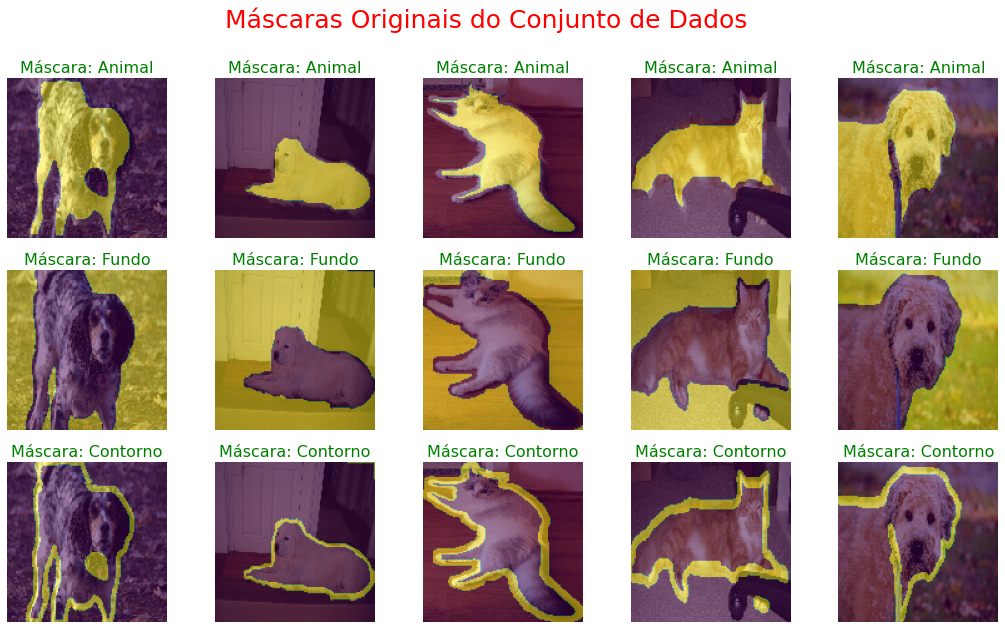

In [214]:
# visualizando os exemplos de imagens e máscaras do conjunto de dados  
fig, axs = plt.subplots(nrows = 3, ncols = 5, figsize = (18, 10))
index = list(map(random.randrange, np.zeros(shape = (5,)), 
                 np.ones(shape = (5,)) * len(image)))
for i in range(0, 3):
  for j in range(0, 5):    
    axs[i, j].imshow(image[index[j]])
    axs[i, j].imshow(mask[index[j]][:, :, 0] == i, alpha = 0.5)
    axs[i, j].set_title('Máscara: ' + class_names[i].capitalize(), size = 16, color = 'green')
    axs[i, j].axis('off')

plt.suptitle('Máscaras Originais do Conjunto de Dados', size = 25, color = 'red')

## 6. Definindo a Rede Neural Artifical para Segmentação Semântica
***

### 6.1 Etapa de Codificação
***

O Codificador usa informações sequenciais de redes neurais convolucionais para extrair as informações da imagem (downsample). Nela, será utilizada camadas do tipo `Conv2D` ativadas por `ReLU`, seguidas uma camada de `MaxPooling` e `Dropout`. Em cada estágio da rede, terá um número crescente de filtros e a dimensionalidade dos recursos tende a reduzir (por esse motivo, o nome de etapa de codificação). A Imagem a seguir ilustra o diagrama arquitetural da construção do codificador. 

![image](https://user-images.githubusercontent.com/58775072/136852739-a683180e-b528-4727-bbb5-697f559396f4.png)


* Para auxiliar a construção do codificador, o código será dividido por partes:
  * **conv2d_block()** -- bloco que adiciona duas camadas de convolução com função de ativação do tipo `ReLU`;
  * **encoder_block()** -- adiciona uma camada de `dropout` e `pooling` nos blocos `conv2d_block()`;
  * **encoder()** -- construindo o codificador por completo;
  * **bottleneck()** -- extração de mais recursos do bloco codificador.
* A imagem vista anteriormente do codificador será o desenho arquitetural fiel das funções a seguir. Posteriormente, os blocos de codificação devem ser conectados aos blocos de decodificação.

In [67]:
def conv2d_block(input_tensor, n_filters, kernel_size = 3):
  '''
   bloco que adiciona duas camadas de convolução com função de ativação do tipo ReLU;

   Args:
    input_tensor (tensor) -- camada de entrada do modelo.
    n_filters (int) -- número de filtros.
    kernel_size (int) -- tamanho do kernel para as convoluções.

  Returns:
    x (tensor) -- características extraídas na convolução.  
  '''

  # camada de entrada da rede
  x = input_tensor
  # conectando duas camadas de convolução com função de ativação ReLU  
  for i in range(2):
    x = tf.keras.layers.Conv2D(filters = n_filters, kernel_size = (kernel_size, kernel_size),
                               kernel_initializer = 'he_normal', padding = 'same')(x)
    x = tf.keras.layers.Activation('relu')(x)
  
  return x  

In [68]:
def encoder_block(inputs, n_filters = 64, pool_size = (2, 2), dropout = 0.3):
  '''
   adiciona uma camada de pooling e dropout nos blocos conv2d_block()

   Args:
    inputs (tensor) -- camada de entrada do modelo.
    n_filters (int) -- número de filtros.
    pool_size (int) -- kernel de pooling.
    dropout (float) -- taxa de neurônios zerados no dropout.

  Returns:
    f (tensor) -- retorna o bloco com camada de pooling.
    p (tensor) -- retorna o bloco com camada de pooling e dropout.
  '''

  # cria um bloco de convolução
  f = conv2d_block(inputs, n_filters = n_filters)
  # adiciona uma camada de pooling
  p = tf.keras.layers.MaxPooling2D(pool_size = pool_size)(f)
  # adiciona uma camada de dropout
  p = tf.keras.layers.Dropout(rate = dropout)(p)

  return f, p

In [69]:
def encoder(inputs):
  '''
   construindo o codificador por completo

   Args:
    inputs (tensor) -- camada de entrada do modelo.
  
  Returns:
    p4 (tensor) -- última camada do codificador.
    (f1, f2, f3, f4) (tensor) -- características de saída de todos os blocos de convolução (sem dropout)
  ''' 

  # primeiro bloco de convolução 
  f1, p1 = encoder_block(inputs = inputs, n_filters = 64, pool_size = (2, 2), dropout = 0.3)
  # segundo bloco de convolução 
  f2, p2 = encoder_block(inputs = p1, n_filters = 128, pool_size = (2, 2), dropout = 0.3)
  # terceiro bloco de convolução 
  f3, p3 = encoder_block(inputs = p2, n_filters = 256, pool_size = (2, 2), dropout = 0.3)
  # quarto bloco de convolução 
  f4, p4 = encoder_block(inputs = p3, n_filters = 512, pool_size = (2, 2), dropout = 0.3)

  return p4, (f1, f2, f3, f4)

In [70]:
def bottleneck(inputs):
  '''
  extração de mais recursos do bloco codificador

  Args:
    inputs (tensor) -- camada de entrada.
  Returns:
    bottle_neck (tensor) -- características de saída com mais recursos extraídos.
  '''
  
  bottle_neck = conv2d_block(inputs, n_filters = 1024)

  return bottle_neck

### 6.2 Etapa de Decodificação
***

Finalmente, temos o decodificador que faz um upsample dos recursos de volta ao tamanho da imagem original. Em cada nível de upsampling, você pegará a saída do bloco codificador correspondente e a concatenará antes de alimentar o próximo bloco decodificador. Isso está resumido na figura abaixo.

![image](https://user-images.githubusercontent.com/58775072/136856397-d7f09304-bb41-4512-a509-da9aff7dd109.png)

* Algumas funções serão importantes para definir o decodificador, sendo elas:
  * **decoder_block()**: define um dos blocos do decodificador da u-net;
  * **decoder()** define o decodificador do u-Net encadeando 4 blocos decodificadores;

In [71]:
def decoder_block(inputs, conv_output, n_filters = 64, kernel_size = 3, strides = 3, dropout = 0.3):
  '''
  define um dos blocos de decodificação da u-net

  Args:
    inputs (tensor) -- camada de entrada.
    conv_output (tensor) -- características extraídas do codificador.
    n_filters (tensor) -- número de filtros.
    kernel_size (int) -- dimensão do kernel.
    strides (int) -- passo do kernel de desconvolução (upsampling).

  Returns:
    c (tensor) -- características extraídas do bloco de decodificação.
  '''
  # aplicando a desconvolução (upsampling)  
  u = tf.keras.layers.Conv2DTranspose(filters = n_filters, kernel_size = kernel_size, 
                                      strides = strides, padding = 'same')(inputs)
  # concatena a camada de desconvolução com a saída do bloco de codificação  
  c = tf.keras.layers.concatenate([u, conv_output])
  # aplicando uma camada de dropout
  c = tf.keras.layers.Dropout(rate = dropout)(c) 
  # aplicando um bloco de convolução 
  c = conv2d_block(c, n_filters, kernel_size = 3)

  return c  


In [72]:
def decoder(inputs, convs, output_channels):
  '''
  define o decodificador do u-Net encadeando 4 blocos decodificadores
  
  Args:
    inputs (tensor) -- camada de entrada
    convs (tuple) -- características extraídas do codificador  
    output_channels (int) -- número das classes  

  Returns:
    outputs (tensor) -- camada de saída com as mesmas dimensões da camada de entrada
  '''
  
  # recebendo as características dos blocos de codificação  
  f1, f2, f3, f4 = convs
  # primeiro bloco de decodificação 
  c6 = decoder_block(inputs, f4, n_filters = 512, kernel_size = (3, 3), strides = (2, 2), dropout = 0.3)
  # segundo bloco de decodificação
  c7 = decoder_block(c6, f3, n_filters = 256, kernel_size = (3, 3), strides = (2, 2), dropout = 0.3)
  # terceiro bloco de decodificação 
  c8 = decoder_block(c7, f2, n_filters = 128, kernel_size = (3, 3), strides = (2, 2), dropout = 0.3)
  # quarto bloco de decodificação
  c9 = decoder_block(c8, f1, n_filters = 64, kernel_size = (3, 3), strides = (2, 2), dropout = 0.3)

  # camada de saída
  outputs = tf.keras.layers.Conv2D(output_channels, (1, 1), activation = 'softmax')(c9)

  return outputs

### 6.3 Codificação e Decodificação
***
* Agora as etapas de codificação e decodificação das redes serão conectadas. Desse modo, teremos uma réplica da arquitetura U-net para realização de segmentação semântica no conjunto de imagens de pets.

In [73]:
def unet():
  '''
  definindo a arquitetura u-net conectando o codificador, bottleneck e o decodificador.

  Returns:
    model (tensor) -- modelo de segmentação semântica baseado na u-net
  '''

  # especificando as dimensões dos dados de entrada
  inputs = tf.keras.layers.Input(shape = (128, 128, 3,))
  # conectando a camada de entrada ao codificador
  encoder_output, convs = encoder(inputs)
  # conectando o codificador ao bottleneck
  bottle_neck = bottleneck(encoder_output)

  # conectando o bottleneck e o codificador ao decodificador  
  outputs = decoder(bottle_neck, convs, output_channels = 3)

  # criando o modelo baseado na arquitetura u-net
  model = tf.keras.models.Model(inputs = inputs, outputs = outputs)

  return model 

In [95]:
# instanciando o modelo de segmentação semântica
model = unet()

In [96]:
# visualizando um resumo da arquitetura
model.summary()

Model: "model_2"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_3 (InputLayer)            [(None, 128, 128, 3) 0                                            
__________________________________________________________________________________________________
conv2d_38 (Conv2D)              (None, 128, 128, 64) 1792        input_3[0][0]                    
__________________________________________________________________________________________________
activation_36 (Activation)      (None, 128, 128, 64) 0           conv2d_38[0][0]                  
__________________________________________________________________________________________________
conv2d_39 (Conv2D)              (None, 128, 128, 64) 36928       activation_36[0][0]              
____________________________________________________________________________________________

## 7. Compilando e Treinando o Modelo
***
Tendo toda a arquitetura e os dados definidos, podemos compilar e treinar o modelo. A função de custo utilizada será a `sparse_categorical_crossentropy`. O motivo da escolha dessa função de custo ocorre devido a organização dos dados de saída, em que a rede estará atribuindo a cada pixel um rótulo, assim como ocorre na previsão multiclasse. Na verdadeira máscara de segmentação, cada pixel será {0, 1, 2}, mas os dados previstos foram organizados para que cada classe fosse separada em diferentes canais da imagem. Essencialmente, cada canal está tentando aprender a prever uma classe, sendo a função de custo `sparse_categorical_crossentropy` a mais adequada para esse tipo de cenário.

In [97]:
# compilando o modelo 
model.compile(optimizer = tf.keras.optimizers.Adam(), 
              loss = 'sparse_categorical_crossentropy',
              metrics = ['acc'])

In [98]:
# criando um callback para salvar os melhores pesso obtidos durante o treinamento do modelo
checkpoint = tf.keras.callbacks.ModelCheckpoint(filepath = 'weights.hdf5', monitor = 'val_acc', 
                                                verbose = True, save_best_only = True, 
                                                save_weights_only = True)
# salvando o histórico de treinamento em um arquivo .csv  
csv_log = tf.keras.callbacks.CSVLogger(filename = 'train_history.csv', separator = ',')
# criando uma lista de callbacks
callbacks = [checkpoint, csv_log]

In [99]:
# configurando os hiperparâmetros de treinamento e treinando o modelo
STEPS_PER_EPOCH = info.splits['train'].num_examples // BATCH_SIZE
VALIDATION_STEPS = info.splits['test'].num_examples // BATCH_SIZE // 5

# treinando o modelo
model_history = model.fit(train_dataset, epochs = 50,
                          steps_per_epoch = STEPS_PER_EPOCH,
                          validation_steps = VALIDATION_STEPS,
                          validation_data = test_dataset,
                          callbacks = callbacks) 

Epoch 1/50
57/57 [==============================] - 27s 458ms/step - loss: 1.0176 - acc: 0.5773 - val_loss: 0.8373 - val_acc: 0.5950

Epoch 00001: val_acc improved from -inf to 0.59502, saving model to weights.hdf5
Epoch 2/50
57/57 [==============================] - 26s 454ms/step - loss: 0.8089 - acc: 0.6023 - val_loss: 0.7907 - val_acc: 0.5973

Epoch 00002: val_acc improved from 0.59502 to 0.59729, saving model to weights.hdf5
Epoch 3/50
57/57 [==============================] - 26s 451ms/step - loss: 0.7399 - acc: 0.6692 - val_loss: 0.6544 - val_acc: 0.7411

Epoch 00003: val_acc improved from 0.59729 to 0.74114, saving model to weights.hdf5
Epoch 4/50
57/57 [==============================] - 26s 451ms/step - loss: 0.6251 - acc: 0.7484 - val_loss: 0.5782 - val_acc: 0.7683

Epoch 00004: val_acc improved from 0.74114 to 0.76828, saving model to weights.hdf5
Epoch 5/50
57/57 [==============================] - 26s 451ms/step - loss: 0.5550 - acc: 0.7796 - val_loss: 0.5118 - val_acc: 0.800

In [ ]:
# carregando os melhores pesos obtidos durante o treinamento do modelo
model.load_weights('/content/weights.hdf5')

## 8. Histórico de Treinamento
***

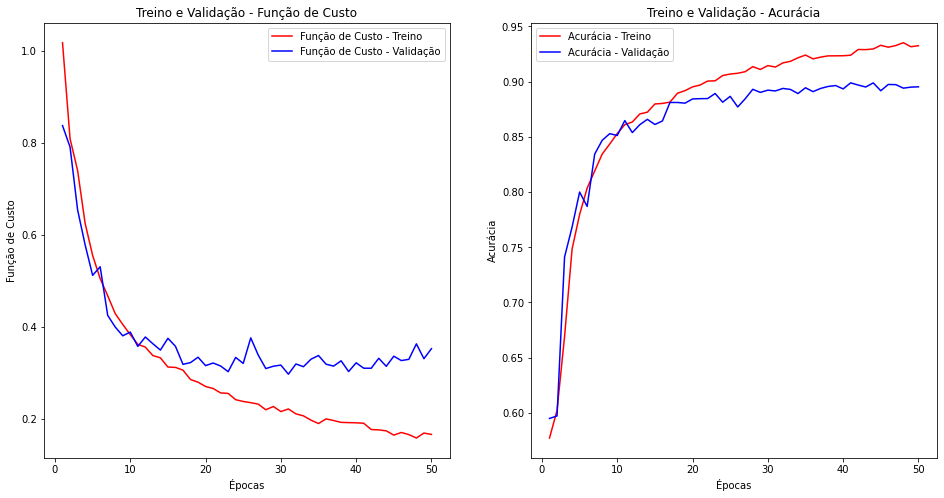

In [101]:
# plotando os resultados obtidos
fig, axes = plt.subplots(1, 2, squeeze = False, figsize = (16, 8))

history_dict = model_history.history

# função de custo nos dados de treino e validação 
train_loss_values = history_dict["loss"]
val_loss_values = history_dict["val_loss"]

# épocas de treinamento 
epochs = range(1, len(train_loss_values) + 1)

# acurácia nos dados de treino e validação  
train_acc_values = history_dict["acc"]
val_acc_values = history_dict["val_acc"]

# plotando o gráfico de função de custo nos dados de treino e validação
ax = axes.flat[0]
ax.plot(epochs, train_loss_values, "r", label = "Função de Custo - Treino")
ax.plot(epochs, val_loss_values, "b", label = "Função de Custo - Validação")
ax.set_title("Treino e Validação - Função de Custo")
ax.set_xlabel("Épocas")
ax.set_ylabel("Função de Custo")
ax.legend()

# plotando o gráfico de acurácia nos dados de treino e validação   
ax = axes.flat[1]
ax.plot(epochs, train_acc_values, "r", label = "Acurácia - Treino")
ax.plot(epochs, val_acc_values, "b", label = "Acurácia - Validação")
ax.set_title("Treino e Validação - Acurácia")
ax.set_xlabel("Épocas")
ax.set_ylabel("Acurácia")
ax.legend() 

## 9. Analisando o Modelo
***

In [144]:
def get_test_image_and_annotation_arrays():
  '''
  carrega as imagens de teste e as máscaras em arrays 

  Returns:
    images (array) -- array multidimensional com as imagens de teste
    y_true_segmentes (array) -- array multidimensional com as máscaras de teste  
  '''

  # removendo a configuração de envio por lotes  
  ds = test_dataset.unbatch()
  # carregando todas as imagens em um único lote  
  ds = ds.batch(info.splits['test'].num_examples)
  
  # criando listas vazias de referências  
  images = list()
  y_true_segments = list()

  # carrega as imagens e as máscaras de teste no formato de array 
  for image, annotation in ds.take(1):
    y_true_segments = annotation.numpy()
    images = image.numpy()
 
  return images, y_true_segments

In [203]:
# carregando as imagens e máscaras de teste
images, y_true_masks = get_test_image_and_annotation_arrays()
# obtendo as máscaras de predição nas imagens de teste  
y_pred_masks = model.predict(images)
# organizando as imagens ao longo dos três canais em um único canal
y_pred_masks_argmax = np.reshape(np.argmax(y_pred_masks, axis = 3), (3669, 128, 128, 1))

In [148]:
# visualizando as dimensões das imagens e máscaras de teste   
print('Quantidade de Imagens de Teste:', len(images), 'Imagens')
print('Dimensão das Máscaras Verdadeiras:', y_true_masks.shape)
print('Dimensão das Máscaras Preditas:', y_pred_masks.shape)

Quantidade de Imagens de Teste: 3669 Imagens
Dimensão das Máscaras Verdadeiras: (3669, 128, 128, 1)
Dimensão das Máscaras Preditas: (3669, 128, 128, 3)


Text(0.5, 0.98, 'Máscaras Originais x Predição do Algoritmo')

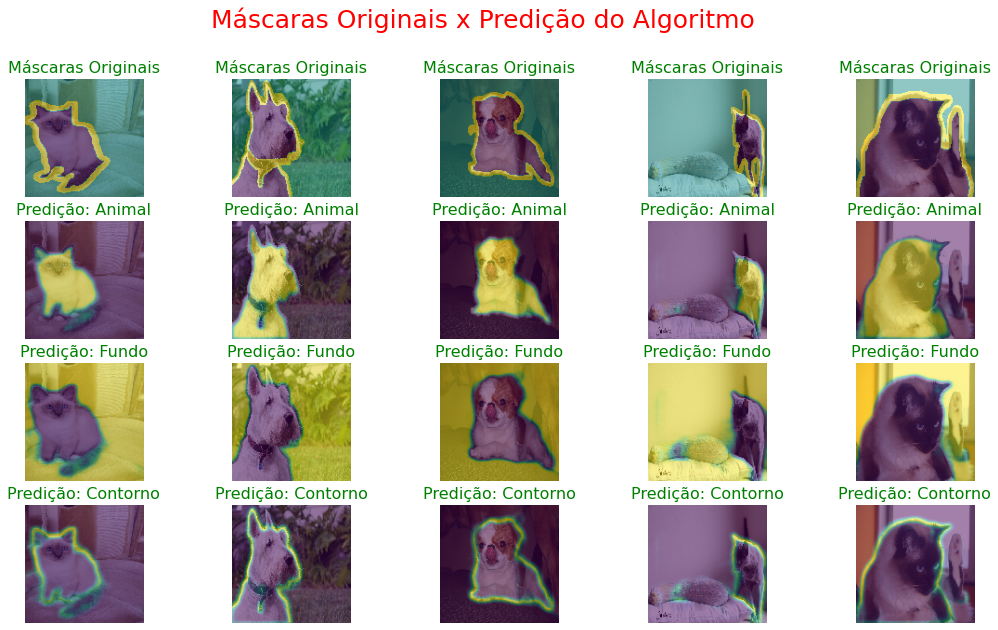

In [178]:
# visualizando os exemplos de imagens e máscaras do conjunto de dados  
fig, axs = plt.subplots(nrows = 4, ncols = 5, figsize = (18, 10))
index = list(map(random.randrange, np.zeros(shape = (5,)), 
                 np.ones(shape = (5,)) * len(images)))
for i in range(0, 4):
  for j in range(0, 5):
    if i == 0:
      axs[i, j].imshow(images[index[j]])
      axs[i, j].imshow(y_true_masks[index[j]][:, :, 0], alpha = 0.5)
      axs[i, j].set_title('Máscaras Originais', size = 16, color = 'green')
      axs[i, j].axis('off')
    else: 
      axs[i, j].imshow(images[index[j]])
      axs[i, j].imshow(y_pred_masks[index[j]][:, :, i - 1], alpha = 0.5)
      axs[i, j].set_title('Predição: ' + class_names[i - 1].capitalize(), size = 16, color = 'green')
      axs[i, j].axis('off')

plt.suptitle('Máscaras Originais x Predição do Algoritmo', size = 25, color = 'red')

In [179]:
def class_wise_metrics(y_true, y_pred):
  '''
  computa o iou e o dice para verificar a precisão da segmentação com relação as máscaras originais

  Args:
    y true (array) -- máscaras originais nos dados de teste
    y_pred (array) -- máscaras preditas nos dados de teste

  Returns:
    class_wise_iou (list) -- métricas de avaliação iou nas imagens de teste
    class_wise_dice_score (list) -- métricas de avaliação dice nas imagens de teste
  '''
  class_wise_iou = []
  class_wise_dice_score = []

  smoothening_factor = 0.00001
  for i in range(3):
    
    intersection = np.sum((y_pred == i) * (y_true == i))
    y_true_area = np.sum((y_true == i))
    y_pred_area = np.sum((y_pred == i))
    combined_area = y_true_area + y_pred_area
    
    iou = (intersection + smoothening_factor) / (combined_area - intersection + smoothening_factor)
    class_wise_iou.append(iou)
    
    dice_score =  2 * ((intersection + smoothening_factor) / (combined_area + smoothening_factor))
    class_wise_dice_score.append(dice_score)

  return class_wise_iou, class_wise_dice_score

In [206]:
# obtendo as métricas de avaliação nos dados de teste
class_wise_iou, class_wise_dice_score = class_wise_metrics(y_true_masks, y_pred_masks_argmax)

print('Métricas de Avaliação:\n--')
print('Intersection Over Union (IoU) - Animal:', class_wise_iou[0])
print('Intersection Over Union (IoU) - Fundo:', class_wise_iou[1])
print('Intersection Over Union (IoU) - Contorno:', class_wise_iou[2], '\n--')
print('Dice similarity (Dice) - Animal:', class_wise_dice_score[0])
print('Dice similarity (Dice) - Fundo:', class_wise_dice_score[1])
print('Dice similarity (Dice) - Contorno:', class_wise_dice_score[2])

Métricas de Avaliação:
--
Intersection Over Union (IoU) - Animal: 0.8051340555144849
Intersection Over Union (IoU) - Fundo: 0.8917155987116903
Intersection Over Union (IoU) - Contorno: 0.4965258624359017 
--
Dice similarity (Dice) - Animal: 0.8920490453937316
Dice similarity (Dice) - Fundo: 0.9427586253653559
Dice similarity (Dice) - Contorno: 0.6635713754095377
